# Figure 4 with trained random features

The original Figure 4 plots the **degree-3 kernel floor** -- the $n\to\infty$ error of the best
degree-3 predictor -- against task diversity $T$, in distribution (query task from the pool) and out
of distribution (fresh $\beta \sim N(0, I)$), next to the dMMSE (memorizing) and Ridge (generalizing)
oracles. This notebook redraws it with **trained models**: fixed random features, one-pass SGD, no
feature learning. If the floors are right, the trained curves land on the old ones.

**Setting** -- `kicl_floor.CONFIG_PAPER`, the one the original figure used: $d=8$, $L_{\rm cfg}=16$
(15 in-context pairs plus the query; the figure's "L=16" counts the query), $\epsilon^2=0.25$,
$\sigma_x^2=1/32$, so $d\,\sigma_x^2=\epsilon^2$: signal-to-noise 1. (Every normalized error is
unchanged by rescaling $x$ and the noise together, so this is the same figure as $\sigma_x^2=1/d$
with $\epsilon^2=1$.) Recomputing the floors and oracles at this setting reproduces the values
read off the original figure to ~0.01 everywhere except T=1 OOD, which sits inside its pool-to-pool
spread (a single task's $|\beta_1|^2$).

**What the figure should show.**

* *In distribution*, the model starts on dMMSE at T=1 (it fits its one task down to the noise
  floor, 0.5 here), rises through Ridge around $T\approx d$ and plateaus above it, while dMMSE climbs
  slowly over all twelve octaves -- memorizing stays the best in-distribution strategy for as long as
  the pool is finite.
* *Out of distribution*, the model falls from the dMMSE level at T=1 onto the same plateau by
  $T\approx 2^5$, and dMMSE only crosses under it around $T\approx 2^8$-$2^9$.

**What it does not show.** At 15 pairs in $d=8$ the context is short, and the degree-3 truncation
of Ridge is visibly above Ridge: the plateau is not "Ridge". That is a property of the degree-3
kernel at this context length, the same in the original figure; the closeness-to-Ridge claim is made
at long context in `rf_ridge_reach.ipynb` / `rf_finality.ipynb`. Here the point is the transition and
the in/out-of-distribution structure, with trained models.

## Colab setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/kernels_can_icl/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 967, done.
remote: Total 967 (delta 0), reused 0 (delta 0), pack-reused 967 (from 1)
Receiving objects: 100% (967/967), 56.14 MiB | 19.23 MiB/s, done.
Resolving deltas: 100% (524/524), done.


In [ ]:
import os, sys, math, time, pickle, dataclasses
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

if not os.path.exists("/content/kernels_can_icl"):
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")
    os.makedirs(RESULTPATH, exist_ok=True)

import kicl_floor as KF
import transience_utils as TU
import structured_rf as SR

# A stale clone pairs this notebook with older modules; fail here, not an hour in.
_missing = [n for n in ("StructuredRF", "StructuredSpectrum", "context_of") if not hasattr(SR, n)]
_missing += [n for n in ("CONFIG_PAPER", "build_ladder_engine", "ladder_pieces") if not hasattr(KF, n)]
if _missing:
    raise RuntimeError(f"stale clone (missing {_missing}). Run `!git -C /content/kernels_can_icl pull`, "
                       "then Runtime > Restart.")

torch.backends.cuda.matmul.allow_tf32 = False     # the in-context channel is ~1e-7 of the top mode
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)}, {GPU_GB:.1f} GB)" if GPU_GB
      else "(CPU -- runs the FIG4_SMOKE version)")

device: cuda (NVIDIA A100-SXM4-40GB, 42.4 GB)


## Configuration

**Error bars are trained.** Each T gets `TRIALS` independent pools (seeded $N(0, I)$ draws, as the
original figure averaged over draws), each trained from scratch; the error bars are the standard
deviation across them, for the model and for the oracles on the same pools. Runs are cheap here -- the
context is 135-dimensional -- so trained repeats cost less than an hour per pass.

**Stopping.** Each run gets the step budget its own pool needs: the theory predicts the whole ID/OOD
curve before training, and the run stops once that curve has settled within `STOP_TOL` of where it
converges. The tolerance is tight (about 0.003 here) because the features that matter are small --
the plateau sits ~0.04 above Ridge.

**Averaging.** At signal-to-noise 1, constant-step SGD does not sit on the optimum but in a noise ball
around it: in the first batch-256 runs every plateau point was ~0.07 above its floor on ID and OOD alike,
flat, and jittering by +-0.04 between evaluations. So after its budget each run averages its weights
over a further stretch (`AVERAGE`), and the figure reports the averaged model.

`FIG4_SMOKE=1` (automatic on CPU) runs a tiny version end to end in a minute or two.

In [ ]:
SMOKE = bool(int(os.environ.get("FIG4_SMOKE", "0"))) or DEVICE.type != "cuda"

CFG       = KF.CONFIG_PAPER               # d=8, L_cfg=16 (15 pairs), eps^2=0.25, sigma_x^2=1/32
POOL_KIND = "normal"                      # beta_i ~ N(0, I), nothing constrained -- as in the original
SEED      = 0
LR_FRAC   = 0.8                           # eta = LR_FRAC * 2 / lambda_1 (measured on the real operator)
WIDTH_FACTOR = 1.5                        # x median ||c - c'||: wide enough to extrapolate like a polynomial
# The step CAP is set by the slowest degree-3 channel (XX) reaching TARGET_L; each run stops earlier
# once its own predicted curve has settled within max(STOP_TOL_ABS, STOP_TOL_REL x floor).
TARGET_FAMILY, TARGET_L = "XX", 0.95
STOP_TOL_ABS, STOP_TOL_REL = 0.003, 0.004
MIN_STEPS = 2_000                         # however little the theory asks for, average the SGD noise
# "Landed" = OOD - floor <= max(LAND_TOL, LAND_REL x floor) + 2 SE of the evaluation.
# The raw-run guard (extend x EXTEND while not landed, up to EXTEND_MAX x the budget) is OFF: at SNR 1
# what it chased was the SGD noise ball -- ID and OOD both lifted ~0.07 and flat, with +-0.04 jitter --
# which more steps cannot remove and the weight averaging below does.
LAND_TOL, LAND_REL, EXTEND, EXTEND_MAX = 0.01, 0.01, 1.25, 1.0
# Tail averaging (Polyak-Ruppert; for least squares, Bach & Moulines 2013). With a constant step SGD
# settles into a cloud around the optimum; the average of the weights over a stretch of that stationary
# run removes it. After its budget each run keeps training for up to AVG_MAX_FRAC x budget steps and
# reports the AVERAGED weights, stopping early once they are on the floor. For a run that already
# finished, the stretch starts where it stopped -- equivalent to averaging its own tail, since it was
# already stationary. The raw run's record is left as it was.
AVERAGE, AVG_MIN, AVG_MAX_FRAC, AVG_SMOKE = True, 20_000, 1.0, 300
# A run that finished in an EARLIER session is final: loaded as it is, never topped up. True lets the
# guard extend those too.
EXTEND_FINISHED = False
# Which T this session trains. None = every T. A list = only those; every other T is read-only (its
# checkpoints are loaded as they are, a T with none is skipped).
TRAIN_TS = None
CKPT_SECONDS = 600

if SMOKE:
    CFG = KF.KICLConfig(dim=8, L_cfg=7, sigma_sq=0.25, sigma_x2=1.0 / 32, name="fig4 smoke")
    T_LIST, TRIALS, TRIALS_AT = [1, 4, 16], 2, {}
    M_FEATURES, BATCH, TEST_SZ, GEN_SHARD = 2_048, 64, 2_048, 4_096
    SMOKE_STEPS, N_PREVIEW = 1_500, 2
else:
    T_LIST = [2 ** k for k in range(11)]  # 1 .. 4096, as in the original
    TRIALS = 3                            # pools per T; the error bars are the SD across them
    TRIALS_AT = {}                        # per-T override, e.g. {8: 5, 16: 5} for more draws in the transition
    M_FEATURES = "auto"                   # context features; the readout is M x d
    BATCH, TEST_SZ = 256, 65_536
    GEN_SHARD = 65_536                    # data made in shards and sliced into batches: at this model size
                                          # per-step generation would otherwise cost more than the step
    SMOKE_STEPS, N_PREVIEW = None, 4

DIM, PAIRS, EPS, SIGMA_X2 = CFG.dim, CFG.L, CFG.e, CFG.v
N_EVAL, EVAL_CHUNK = 30, 512

def trials_for(T):
    return TRIALS_AT.get(T, TRIALS)

print(CFG.describe())
print(f"SMOKE={SMOKE}  d={DIM}  {PAIRS} pairs  eps^2={EPS}  sigma_x^2={SIGMA_X2:g} (d sigma_x^2 / eps^2 = "
      f"{DIM * SIGMA_X2 / EPS:g})  w={WIDTH_FACTOR}x")
print(f"T = {T_LIST}\n   -> {sum(trials_for(T) for T in T_LIST)} runs; this session trains "
      f"{'every T' if TRAIN_TS is None else TRAIN_TS}")

paper Fig 4: d=8 L_cfg=16 (L=15 pairs) e=0.25 v=0.03125 sigma_beta2=1.0 D=143 norm2=0.50000
SMOKE=False  d=8  15 pairs  eps^2=0.25  sigma_x^2=0.03125 (d sigma_x^2 / eps^2 = 1)  w=1.5x
T = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
   -> 33 runs; this session trains every T


## Width and sizing

The kernel acts on the context $c=[X,y]$ only, so its width is calibrated on context vectors, and
neither the kernel nor M depends on T. In the channel table, `Xy` (the in-context channel) and `XX`
must have ceilings near 1, and the degree-5 `y3X` / `y2XX` (the tail of dMMSE $-$ Ridge that would let
the model start memorizing) must be ~0 -- then the trained model lands on the degree-3 floor, which
is what the original figure plotted.

In [ ]:
_td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
_, _, _Xc, _yc, _Xq = TU.gen_raw(_td, CFG, 3000, "pretrain")
_C = SR.context_of(_Xc, _yc)
MEDIAN_CTX = float(torch.cdist(_C[:1500].double(), _C[1500:].double()).flatten().median())
WIDTH = WIDTH_FACTOR * MEDIAN_CTX
D_CTX = _C.shape[1]
SPEC = SR.StructuredSpectrum(CFG, WIDTH)
print(f"D_ctx = {D_CTX}   median||c - c'|| = {MEDIAN_CTX:.3f}   width = {WIDTH:.3f} ({WIDTH_FACTOR}x)")

_per_feature = 4 * (D_CTX + BATCH + EVAL_CHUNK) + 8 * DIM
if M_FEATURES == "auto":
    M_FEATURES = 2 ** math.ceil(math.log2(SPEC.M_for(TARGET_FAMILY, TARGET_L)))
    if GPU_GB and M_FEATURES * _per_feature > 0.4 * GPU_GB * 1e9:
        M_FEATURES = 2 ** int(math.log2(0.4 * GPU_GB * 1e9 / _per_feature))
        print(f"capped by memory: M = {M_FEATURES:,}")
L_CEIL = SPEC.L_ceiling(TARGET_FAMILY, M_FEATURES)

_model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, SEED, DEVICE)
LAM1 = _model.top_eigenvalue(_C[:512].to(DEVICE), _Xq[:512].squeeze(1).to(DEVICE))
ETA = LR_FRAC * 2.0 / LAM1
MAX_STEPS = int(math.ceil(SPEC.steps_for(TARGET_FAMILY, ETA, LAM1, min(TARGET_L, 0.999 * L_CEIL))))
del _model

print(f"M = {M_FEATURES:,} context features ({M_FEATURES * DIM:,} parameters)")
print(f"lambda_1 {LAM1:.4f} -> eta {ETA:.2f};  step cap {MAX_STEPS:,} -- each run stops earlier if it can")
print(f"\n{'channel':>8} {'lambda/lam1':>12} {'M for L=.9':>12} {'ceiling here':>13} {'steps':>12}")
for row in SPEC.describe(M_FEATURES, ETA, LAM1):
    print(f"{row[0]:>8} {row[1]:>12} {row[2]:>12} {row[3]:>13} {row[4] if len(row) > 4 else '':>12}")
_mem = max(SPEC.L_ceiling(k, M_FEATURES) for k in ("y3X", "y2XX"))
print(f"\ndegree-5 ceiling at this M: {_mem:.4f} -- " +
      ("out of reach: the trained model can only land on the degree-3 floor." if _mem < 0.05 else
       "NOT negligible: the model can partly implement the degree-5 tail, so it may drift below the "
       "degree-3 floor toward dMMSE. Lower M to keep it on the floor."))

D_ctx = 135   median||c - c'|| = 4.664   width = 6.996 (1.5x)
M = 16,384 context features (131,072 parameters)
lambda_1 0.0286 -> eta 56.01;  step cap 4,603,945 -- each run stops earlier if it can

 channel  lambda/lam1   M for L=.9  ceiling here        steps
       q    1.000e+00            1         1.000            1
      y2    1.003e-04        1,032         1.000       14,354
      Xy    6.385e-06        4,570         0.998      225,377
      XX    4.067e-07       11,219         0.963    3,538,692
     y3X    6.402e-10      584,249         0.039   38,885,643
    y2XX    4.077e-11    2,873,729         0.003   39,620,706

degree-5 ceiling at this M: 0.0391 -- out of reach: the trained model can only land on the degree-3 floor.


## What the run should produce

Floors and oracles for `N_PREVIEW` pool draws per T -- the trained curves should land here. Next to
them, the values read off the original figure: they should agree everywhere except T=1 OOD, whose
spread across draws is large.

In [ ]:
_pre3 = KF.build_floor_engine(CFG, (3,))[3]
# read off the original Figure 4 (T = 2^0 .. 2^12); only meaningful at CONFIG_PAPER
ORIG = None if SMOKE else dict(
    fi=[0.500, 0.550, 0.625, 0.677, 0.694, 0.742, 0.760, 0.757, 0.757, 0.763, 0.765, 0.764, 0.765],
    fo=[1.390, 1.215, 1.035, 0.888, 0.835, 0.795, 0.776, 0.773, 0.773, 0.767, 0.767, 0.766, 0.766],
    di=[0.497, 0.507, 0.520, 0.541, 0.568, 0.590, 0.613, 0.650, 0.664, 0.688, 0.695, 0.707, 0.713],
    do=[1.395, 1.282, 1.165, 1.007, 0.945, 0.888, 0.840, 0.805, 0.775, 0.765, 0.745, 0.733, 0.720])
print(f"{'T':>5} | {'floor ID':>8} {'(orig)':>7} {'floor OOD':>9} {'(orig)':>7} | {'dMMSE ID':>8} {'(orig)':>7} "
      f"{'dMMSE OOD':>9} {'(orig)':>7} | {'Ridge':>6}")
PREVIEW = {}
for _i, _T in enumerate(T_LIST):
    _f, _o = [], []
    for _t in range(N_PREVIEW):
        torch.manual_seed(SEED + 1009 * _t + 17 * _T)
        _b = KF.draw_betas(_T, CFG, POOL_KIND, torch.device("cpu"))
        _f.append(KF.ood_floors_fast(_pre3, _b, CFG.sigma_beta2))
        _o.append(KF.oracle_mse_one_betas(_b, DIM, CFG.L_cfg, CFG.v, CFG.e, 1.0, CFG.norm2, 1500,
                                          np.random.default_rng(_t)))
    PREVIEW[_T] = dict(fi=float(np.mean([f[0] for f in _f])), fo=float(np.mean([f[1] for f in _f])),
                       di=float(np.mean([o["dmmse_id"] for o in _o])), do=float(np.mean([o["dmmse_ood"] for o in _o])),
                       r=float(np.mean([o["ridge_ood"] for o in _o])))
    _p = PREVIEW[_T]
    _og = (lambda k: f"{ORIG[k][_i]:>7.3f}") if ORIG and _i < len(ORIG["fi"]) else (lambda k: f"{'':>7}")
    print(f"{_T:>5} | {_p['fi']:>8.3f} {_og('fi')} {_p['fo']:>9.3f} {_og('fo')} | {_p['di']:>8.3f} {_og('di')} "
          f"{_p['do']:>9.3f} {_og('do')} | {_p['r']:>6.3f}")

    T | floor ID  (orig) floor OOD  (orig) | dMMSE ID  (orig) dMMSE OOD  (orig) |  Ridge
    1 |    0.500   0.500     1.466   1.390 |    0.510   0.497     1.437   1.395 |  0.722
    2 |    0.550   0.550     1.172   1.215 |    0.525   0.507     1.272   1.282 |  0.744
    4 |    0.614   0.625     1.047   1.035 |    0.542   0.520     1.171   1.165 |  0.744
    8 |    0.687   0.677     0.904   0.888 |    0.546   0.541     1.075   1.007 |  0.744
   16 |    0.708   0.694     0.834   0.835 |    0.575   0.568     0.960   0.945 |  0.744
   32 |    0.745   0.742     0.800   0.795 |    0.601   0.590     0.908   0.888 |  0.744
   64 |    0.752   0.760     0.780   0.776 |    0.624   0.613     0.861   0.840 |  0.744
  128 |    0.757   0.757     0.771   0.773 |    0.649   0.650     0.805   0.805 |  0.744
  256 |    0.762   0.757     0.769   0.773 |    0.676   0.664     0.802   0.775 |  0.744
  512 |    0.766   0.763     0.767   0.767 |    0.692   0.688     0.776   0.765 |  0.744
 1024 |    0.766   0.

## How long each run needs

One-pass SGD gives each ladder feature learnability $L_i(t) = L_i^{\rm ceil}(1-e^{-\eta\lambda_i t})$,
and `kicl_floor.ladder_pieces` + `score_learnability` turn that into the predicted ID and OOD curve of
this pool, so each run's budget is read off before it trains. The runtime estimate below times the
actual step on this GPU.

In [ ]:
LAD3 = KF.build_ladder_engine(CFG, ladder=KF.LADDER[:4], max_degree=3)[-1][1]
_CEIL = {k: SPEC.L_ceiling(k, M_FEATURES) for k, _, _ in KF.LADDER[:4]}

def seed_for(T, trial):
    return SEED + 1009 * trial + 17 * T

def pool_betas(T, trial):
    """Exactly the pool TU.make_pool_distr draws for this seed, float32 round-trip included."""
    seed = seed_for(T, trial)
    torch.manual_seed(seed)
    np.random.seed(seed % (2 ** 31))
    b = KF.draw_betas(T, CFG, POOL_KIND, torch.device("cpu"))
    return torch.as_tensor(b, dtype=torch.float32).double().numpy()

def steps_needed(betas, n_grid=400):
    """(steps, predicted ID, predicted OOD) for this pool: when its curve settles within STOP_TOL."""
    pieces = KF.ladder_pieces(LAD3, betas, CFG.sigma_beta2)
    rel = np.array([SPEC.family[f] for f in pieces["fam"]])
    ceil = np.array([_CEIL[f] for f in pieces["fam"]])
    end = np.array(KF.score_learnability(pieces, ceil))
    tol = max(STOP_TOL_ABS, STOP_TOL_REL * float(end[1]))
    grid = np.geomspace(max(1, MIN_STEPS // 10), MAX_STEPS, n_grid)
    dev = np.array([np.abs(np.array(KF.score_learnability(
        pieces, ceil * (1 - np.exp(-ETA * LAM1 * rel * t)))) - end).max() for t in grid])
    bad = np.nonzero(dev > tol)[0]
    s = grid[min(bad[-1] + 1, n_grid - 1)] if len(bad) else grid[0]
    return int(np.clip(s, MIN_STEPS, MAX_STEPS)), float(end[0]), float(end[1])

STEPS_AT = {(T, t): steps_needed(pool_betas(T, t)) for T in T_LIST for t in range(trials_for(T))}
print(f"{'T':>5} | " + " ".join(f"{'trial ' + str(t):>10}" for t in range(max(trials_for(T) for T in T_LIST))))
for T in T_LIST:
    print(f"{T:>5} | " + " ".join(f"{STEPS_AT[(T, t)][0]:>10,}" for t in range(trials_for(T))))
print(f"\ntotal {sum(s for s, _, _ in STEPS_AT.values()):,} steps over {len(STEPS_AT)} runs")

def estimate_runtime():
    m = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, 0, DEVICE)
    td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, 4 * BATCH, "pretrain")      # warm-up
    for i in range(3):
        m.step(SR.context_of(Xc, yc)[:BATCH], Xq.squeeze(1)[:BATCH], yq[:BATCH], ETA)
    n = GEN_SHARD // BATCH                                             # one full shard, generation included
    sync(); t0 = time.time()
    _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, GEN_SHARD, "pretrain")
    C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
    for i in range(n):
        s = slice(i * BATCH, (i + 1) * BATCH)
        m.step(C[s], xq[s], yq[s], ETA)
    sync()
    per = (time.time() - t0) / n
    del m
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    ev = 2 * TEST_SZ / BATCH * per * N_EVAL
    trains = lambda T: TRAIN_TS is None or T in TRAIN_TS
    keys = [k for k in STEPS_AT if trains(k[0])]
    first = [k for k in keys if k[1] == 0]
    hrs = lambda ks: sum(STEPS_AT[k][0] * per + ev for k in ks) / 3600
    print(f"{per * 1e3:.3f} ms/step (incl. data generation), ~{ev / 60:.1f} min of evaluation per run")
    print(f"first pass, one pool per T: {len(first)} runs = {hrs(first):.2f} h")
    print(f"all {len(keys)} runs: {hrs(keys):.2f} h  (upper bound: finished runs are skipped; the landing "
          f"guard can add up to {EXTEND_MAX - 1:g}x on a slow pool)")

estimate_runtime()

    T |    trial 0    trial 1    trial 2
    1 |      2,000      2,000      2,000
    2 |  1,860,189    311,418  1,483,077
    4 |  3,077,576  2,006,110  1,956,240
    8 |  1,212,560    831,217    362,192
   16 |    248,285    248,285    254,614
   32 |    732,911    254,614    327,498
   64 |    224,502    224,502    242,112
  128 |    224,502    224,502    224,502
  256 |    218,921    224,502    218,921
  512 |    218,921    218,921    218,921
 1024 |    218,921    218,921    218,921

total 18,513,278 steps over 33 runs
0.336 ms/step (incl. data generation), ~0.1 min of evaluation per run
first pass, one pool per T: 11 runs = 0.79 h
all 33 runs: 1.78 h  (upper bound: finished runs are skipped; the landing guard can add up to 0x on a slow pool)


## The runs

One run per (T, trial): its own pool, its own feature draw, one-pass SGD on a stream that never
repeats a sample. Trial 0 of every T comes first, so an interrupted session still leaves a complete
curve. Each run checkpoints to its own file; re-running this cell resumes unfinished runs and never
changes finished ones (unless `EXTEND_FINISHED = True`).

After the raw run comes the **averaging phase**: the run keeps training and accumulates the running
mean of its weights, evaluating that mean at ~10 points and stopping once it is on the floor (or after
`AVG_MAX_FRAC` x the budget). Runs that finished before averaging existed get it on the next re-run,
starting from their saved weights -- the raw record is untouched, and the averaged one is stored
alongside it.

In [ ]:
TAG = (f"d{DIM}p{PAIRS}e{EPS:g}_sx{SIGMA_X2:g}_{POOL_KIND}_M{M_FEATURES}_b{BATCH}_w{WIDTH_FACTOR}"
       f"{'_smoke' if SMOKE else ''}")
PRE3 = KF.build_floor_engine(CFG, (3,))[3]

def ckpt_path(T, trial):
    return os.path.join(RESULTPATH, f"rf_newfig4_{TAG}_T{T}_t{trial}.pt")

def _fingerprint(T, trial, seed):
    return dict(dim=DIM, pairs=PAIRS, eps=EPS, sigma_x2=SIGMA_X2, M=M_FEATURES, batch=BATCH,
                width=round(WIDTH, 6), T=T, pool=POOL_KIND, test_sz=TEST_SZ, seed=seed)

def _same(got, fp):
    approx = {"width", "sigma_x2", "eps"}
    return (isinstance(got, dict) and set(got) == set(fp)
            and all(math.isclose(got[k], fp[k], rel_tol=1e-3) if k in approx else got[k] == fp[k] for k in fp))

def save_ckpt(path, obj, attempts=4):
    for i in range(attempts):
        try:
            torch.save(obj, path + ".tmp")
            os.replace(path + ".tmp", path)
            return True
        except Exception as err:
            print(f"   checkpoint write failed ({err}); retry {i + 1}")
            time.sleep(2 + 3 * i)
    return False

def _landed(curve, ref):
    """Within tolerance of the floor, allowing for the last evaluation's own test-set noise."""
    if not curve:
        return False
    fl, last = ref["floor3"]["ood"], curve[-1]
    return last["ood"] - fl <= max(LAND_TOL, LAND_REL * fl) + 2 * last.get("ood_se", 0.0)

def _record(T, trial, seed, curve, budget, ref, avg):
    return dict(T=T, trial=trial, seed=seed, curve=curve, budget=budget,
                avg_curve=list((avg or {}).get("curve", [])), **ref)

def final_point(r):
    """What the figure plots for a run: the averaged weights if it has them, else its last evaluation."""
    return r["avg_curve"][-1] if r.get("avg_curve") else r["curve"][-1]

def train_run(T, trial):
    seed = seed_for(T, trial)
    path, fp = ckpt_path(T, trial), _fingerprint(T, trial, seed)
    td, betas = TU.make_pool_distr(CFG, T, seed, POOL_KIND, DEVICE)
    budget, pred_id, pred_ood = STEPS_AT.get((T, trial)) or steps_needed(betas)
    limit = min(MAX_STEPS, int(EXTEND_MAX * budget))
    eval_steps = sorted({max(1, int(round(s))) for s in np.geomspace(1, budget, N_EVAL)})

    trainable = TRAIN_TS is None or T in TRAIN_TS
    st = torch.load(path, map_location="cpu", weights_only=False) if os.path.exists(path) else None
    if st is not None and not _same(st.get("fingerprint"), fp):
        print(f"T={T:>4} trial {trial}: checkpoint is from a different configuration -- "
              + ("starting over" if trainable else "skipped (read-only)"))
        if not trainable:
            return None
        st = None
    if not trainable:
        if st is None:
            print(f"T={T:>4} trial {trial}: not in TRAIN_TS and no checkpoint -- skipped")
            return None
        print(f"T={T:>4} trial {trial}: loaded read-only ({int(st['step']):,} steps)")
        return _record(T, trial, seed, list(st["curve"]), budget, st["ref"], st.get("avg"))

    tests = TU.make_tests(td, CFG, {"id": (TEST_SZ, "pretrain"), "ood": (TEST_SZ, "true")}, seed)
    ctx = {k: (SR.context_of(v["Xc"], v["yc"]), v["Xq"].squeeze(1)) for k, v in tests.items()}
    model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, seed, DEVICE)
    avg, raw_done = None, False
    if st is not None:
        model.load(st); start, curve, ref = int(st["step"]), list(st["curve"]), st["ref"]
        avg = st.get("avg")
        if avg is not None:
            avg = dict(avg, sum=avg["sum"].to(DEVICE))
        # The raw run is final once it reached its budget in an earlier session (EXTEND_FINISHED); the
        # averaging phase continues from its last weights without touching its record.
        raw_done = start >= budget and (not EXTEND_FINISHED or _landed(curve, ref) or start >= limit
                                        or SMOKE_STEPS is not None or avg is not None)
        if raw_done and (not AVERAGE or (avg is not None and avg["done"])):
            print(f"T={T:>4} trial {trial}: complete ({start:,} steps)")
            return _record(T, trial, seed, curve, budget, ref, avg)
        print(f"T={T:>4} trial {trial}: " + (f"raw run finished at step {start:,}" if raw_done
                                             else f"resuming at step {start:,} (budget {budget:,})"))
    else:
        fl = KF.ood_floors_fast(PRE3, betas, CFG.sigma_beta2)
        orc = {}
        for side in ("id", "ood"):
            pr, pd_ = TU.oracle_preds(tests[side]["Xc"], tests[side]["yc"], tests[side]["Xq"], betas, CFG)
            orc[f"ridge_{side}"] = TU.nmse(pr, tests[side]["y"], CFG)
            orc[f"dmmse_{side}"] = TU.nmse(pd_, tests[side]["y"], CFG)
        ref = dict(floor3=dict(id=float(fl[0]), ood=float(fl[1])), oracles=orc, betas=betas,
                   predicted=dict(id=pred_id, ood=pred_ood))
        start, curve = 0, []
        print(f"T={T:>4} trial {trial}: fresh. floor ID {fl[0]:.4f} OOD {fl[1]:.4f} | dMMSE ID "
              f"{orc['dmmse_id']:.4f} OOD {orc['dmmse_ood']:.4f} | Ridge {orc['ridge_ood']:.4f} | {budget:,} steps")

    def evaluate(step):
        row = dict(step=step, n=step * BATCH)
        for side in ("id", "ood"):
            p = model.predict(*ctx[side], chunk=EVAL_CHUNK)
            row[side], row[f"{side}_se"] = TU.nmse_se(p, tests[side]["y"], CFG)
        return row

    stop = budget if SMOKE_STEPS is None else min(budget, SMOKE_STEPS)
    step = start
    while not raw_done:
        t_ck = time.time()
        while step < stop:
            _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, GEN_SHARD, "pretrain")   # one shard, sliced into batches
            C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
            for i in range(0, GEN_SHARD - BATCH + 1, BATCH):
                step += 1
                s = slice(i, i + BATCH)
                model.step(C[s], xq[s], yq[s], ETA)
                if step in eval_steps or step == stop:
                    row = evaluate(step)
                    curve.append(row)
                    print(f"   step {step:>9,}  n_seen {step * BATCH:>12,}  ID {row['id']:.4f}  OOD {row['ood']:.4f}")
                if step >= stop:
                    break
            if time.time() - t_ck > CKPT_SECONDS or step >= stop:
                save_ckpt(path, dict(fingerprint=fp, step=step, curve=curve, ref=ref, **model.state()))
                t_ck = time.time()
        start = max(start, stop)
        # A pool that barely spans one direction learns the in-context channel along it slowly (rate
        # lambda_Xy x s_min), so it can still be descending when the predicted budget ends. The floor is
        # known exactly: keep going while measurably above it, up to EXTEND_MAX x the budget. This only
        # ever trains longer; it never selects on OOD.
        if SMOKE_STEPS is not None or step >= limit or _landed(curve, ref):
            break
        stop = min(limit, int(step * EXTEND))
        print(f"   OOD {curve[-1]['ood']:.4f} is still {curve[-1]['ood'] - ref['floor3']['ood']:+.4f} above its "
              f"floor: extending to {stop:,}")
    if not raw_done and SMOKE_STEPS is None and EXTEND_MAX > 1 and not _landed(curve, ref):
        print(f"   stopped at {step:,} still {curve[-1]['ood'] - ref['floor3']['ood']:+.4f} above the floor "
              f"(EXTEND_MAX reached): this point will sit above its floor.")

    if AVERAGE:
        avg_max = AVG_SMOKE if SMOKE_STEPS is not None else max(AVG_MIN, int(AVG_MAX_FRAC * budget))
        first = min(AVG_MIN, avg_max) if SMOKE_STEPS is None else max(1, avg_max // 4)
        checks = {int(round(x)) for x in np.geomspace(first, avg_max, 10)}
        if avg is None:
            avg = dict(sum=torch.zeros_like(model.U), n=0, from_step=step, curve=[], done=False)
            print(f"   averaging the weights from step {step:,} (at most {avg_max:,} more steps)")
        t_ck = time.time()
        while not avg["done"]:
            _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, GEN_SHARD, "pretrain")
            C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
            for i in range(0, GEN_SHARD - BATCH + 1, BATCH):
                step += 1
                s = slice(i, i + BATCH)
                model.step(C[s], xq[s], yq[s], ETA)
                avg["sum"] += model.U
                avg["n"] += 1
                if avg["n"] in checks or avg["n"] >= avg_max:
                    U_raw = model.U
                    model.U = avg["sum"] / avg["n"]            # evaluate the averaged weights ...
                    row = evaluate(step)
                    model.U = U_raw                            # ... and keep training the raw ones
                    row["n_avg"] = avg["n"]
                    avg["curve"].append(row)
                    print(f"   averaged over {avg['n']:>9,} steps: ID {row['id']:.4f}  OOD {row['ood']:.4f}  "
                          f"({row['ood'] - ref['floor3']['ood']:+.4f} vs floor)")
                    if avg["n"] >= avg_max or (avg["n"] >= first and _landed(avg["curve"], ref)):
                        avg["done"] = True
                        break
            if time.time() - t_ck > CKPT_SECONDS or avg["done"]:
                save_ckpt(path, dict(fingerprint=fp, step=step, curve=curve, ref=ref,
                                     avg=dict(avg, sum=avg["sum"].cpu()), **model.state()))
                t_ck = time.time()
        if SMOKE_STEPS is None and not _landed(avg["curve"], ref):
            print(f"   averaged model still {avg['curve'][-1]['ood'] - ref['floor3']['ood']:+.4f} above its floor "
                  f"after {avg['n']:,} steps (AVG_MAX_FRAC reached): this point will sit above its floor.")
    return _record(T, trial, seed, curve, budget, ref, avg)

records = []
t_all = time.time()
for trial in range(max([TRIALS] + list(TRIALS_AT.values()))):
    for T in T_LIST:
        if trial >= trials_for(T):
            continue
        rec = train_run(T, trial)
        if rec is not None:
            records.append(rec)
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
SUMMARY = os.path.join(RESULTPATH, f"rf_newfig4_{TAG}_summary.pkl")
with open(SUMMARY, "wb") as f:
    pickle.dump(dict(records=records, preview=PREVIEW, config=dataclasses.asdict(CFG), M=M_FEATURES,
                     batch=BATCH, width=WIDTH, eta=ETA, lam1=LAM1, max_steps=MAX_STEPS, steps_at=STEPS_AT,
                     pool=POOL_KIND, stop_tol=(STOP_TOL_ABS, STOP_TOL_REL)), f)
print(f"\ndone in {(time.time() - t_all) / 60:.1f} min -> {SUMMARY}")

T=   1 trial 0: complete (26,000 steps)
T=   2 trial 0: complete (1,880,189 steps)
T=   4 trial 0: complete (3,097,576 steps)
T=   8 trial 0: complete (1,232,560 steps)
T=  16 trial 0: complete (407,945 steps)
T=  32 trial 0: complete (936,138 steps)
T=  64 trial 0: complete (693,506 steps)
T= 128 trial 0: complete (693,506 steps)
T= 256 trial 0: complete (676,763 steps)
T= 512 trial 0: complete (676,763 steps)
T=1024 trial 0: complete (676,763 steps)
T=   1 trial 1: complete (22,000 steps)
T=   2 trial 1: complete (506,590 steps)
T=   4 trial 1: complete (2,527,637 steps)
T=   8 trial 1: complete (1,059,021 steps)
T=  16 trial 1: complete (626,163 steps)
T=  32 trial 1: complete (783,842 steps)
T=  64 trial 1: complete (458,478 steps)
T= 128 trial 1: complete (693,506 steps)
T= 256 trial 1: complete (693,506 steps)
T= 512 trial 1: complete (676,763 steps)
T=1024 trial 1: complete (238,921 steps)
T=   1 trial 2: complete (22,000 steps)
T=   2 trial 2: fresh. floor ID 0.5401 OOD 1.1912 

## Figure 4, trained

Error bars are the standard deviation across the pools at each T, for the model and for the oracles
on the same pools. The thin dashed blue line is the degree-3 floor of those same pools -- the original
figure's curve -- so you can see the trained model land on it.

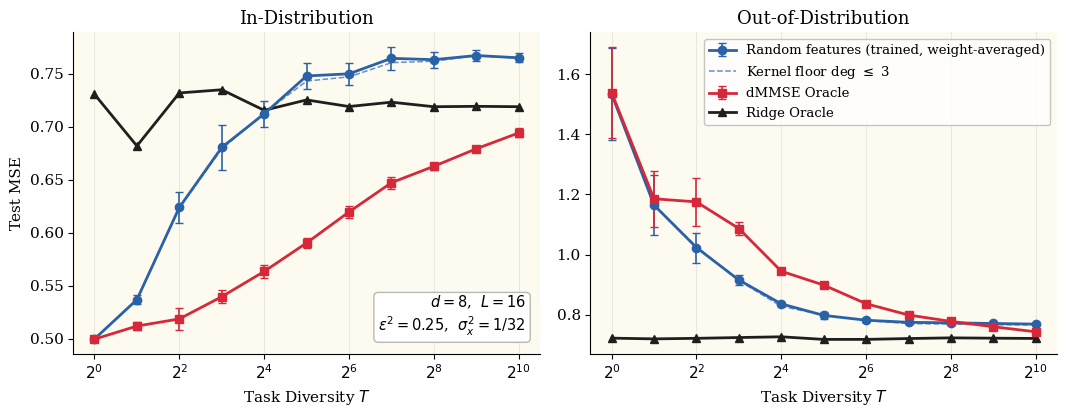

In [ ]:
def per_T(fn):
    """(mean, SD) over the runs at each T of fn(record)."""
    out = []
    for T in Ts:
        v = [fn(r) for r in records if r["T"] == T]
        out.append((float(np.mean(v)), float(np.std(v)) if len(v) > 1 else 0.0))
    return np.array(out)

Ts = [T for T in T_LIST if any(r["T"] == T for r in records)]
assert Ts, "no runs trained or loaded -- check TRAIN_TS and that the checkpoints are in RESULTPATH"

BLUE, RED, INK, BG = "#2a62a8", "#d62839", "#1f1f1e", "#fdfaf0"   # CVD-checked (red/blue dE 17.4)
plt.rcParams.update({"font.family": "serif", "font.size": 11, "axes.titlesize": 13})
fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.3))
for ax, side, title in ((axs[0], "id", "In-Distribution"), (axs[1], "ood", "Out-of-Distribution")):
    ax.set_facecolor(BG)
    kw = dict(capsize=3, lw=2, ms=6, elinewidth=1.2)
    m = per_T(lambda r: final_point(r)[side])
    f3 = per_T(lambda r: r["floor3"][side])
    dm = per_T(lambda r: r["oracles"][f"dmmse_{side}"])
    rg = per_T(lambda r: r["oracles"][f"ridge_{side}"])
    hm = ax.errorbar(Ts, m[:, 0], yerr=m[:, 1], fmt="-o", color=BLUE, zorder=4, **kw)
    hf, = ax.plot(Ts, f3[:, 0], "--", color=BLUE, lw=1.1, alpha=0.7, zorder=3)
    hd = ax.errorbar(Ts, dm[:, 0], yerr=dm[:, 1], fmt="-s", color=RED, zorder=4, **kw)
    hr, = ax.plot(Ts, rg[:, 0], "-^", color=INK, lw=2, ms=6, zorder=4)
    ax.set_xscale("log", base=2)
    ticks = [T for T in Ts if round(math.log2(T)) % 2 == 0]
    ax.set_xticks(ticks); ax.set_xticklabels([f"$2^{{{int(round(math.log2(T)))}}}$" for T in ticks])
    ax.minorticks_off(); ax.grid(axis="x", color="#ebe8dd", lw=0.8); ax.set_title(title)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.set_xlabel("Task Diversity $T$")
axs[0].set_ylabel("Test MSE")
axs[0].text(0.97, 0.05, f"$d={DIM}$,  $L={CFG.L_cfg}$\n" + r"$\epsilon^2$" + f"$={EPS:g}$,  " + r"$\sigma_x^2$"
            + f"$=1/{round(1 / SIGMA_X2)}$", transform=axs[0].transAxes, ha="right", va="bottom", fontsize=10.5,
            bbox=dict(boxstyle="round", fc="white", ec="#b9b8b1"))
_lab = "Random features (trained" + (", weight-averaged)" if any(r.get("avg_curve") for r in records) else ")")
axs[1].legend([hm, hf, hd, hr], [_lab, r"Kernel floor deg $\leq$ 3", "dMMSE Oracle",
                                 "Ridge Oracle"], fontsize=9.5, loc="upper right", frameon=True,
              facecolor="white", edgecolor="#b9b8b1")
fig.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIGDIR, f"rf_newfig4_{TAG}.{ext}"), dpi=200, bbox_inches="tight")
plt.show()

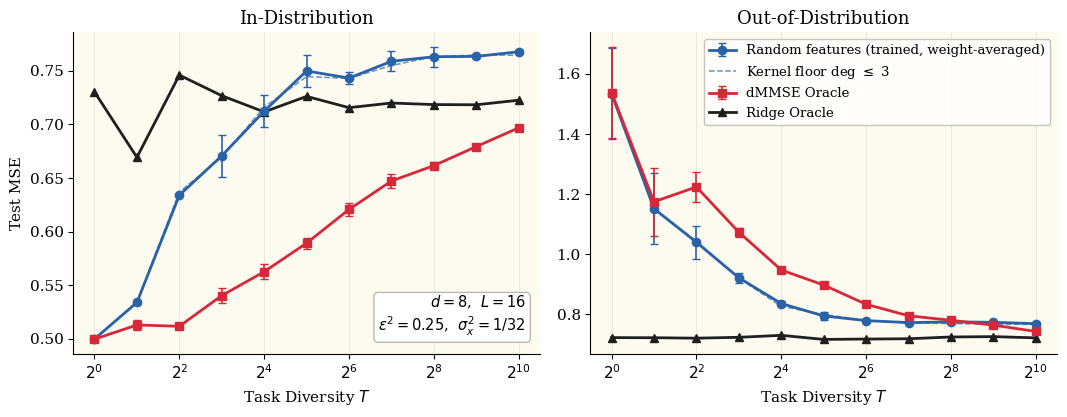

In [ ]:
def per_T(fn):
    """(mean, SD) over the runs at each T of fn(record)."""
    out = []
    for T in Ts:
        v = [fn(r) for r in records if r["T"] == T]
        out.append((float(np.mean(v)), float(np.std(v)) if len(v) > 1 else 0.0))
    return np.array(out)

Ts = [T for T in T_LIST if any(r["T"] == T for r in records)]
assert Ts, "no runs trained or loaded -- check TRAIN_TS and that the checkpoints are in RESULTPATH"

BLUE, RED, INK, BG = "#2a62a8", "#d62839", "#1f1f1e", "#fdfaf0"   # CVD-checked (red/blue dE 17.4)
plt.rcParams.update({"font.family": "serif", "font.size": 11, "axes.titlesize": 13})
fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.3))
for ax, side, title in ((axs[0], "id", "In-Distribution"), (axs[1], "ood", "Out-of-Distribution")):
    ax.set_facecolor(BG)
    kw = dict(capsize=3, lw=2, ms=6, elinewidth=1.2)
    m = per_T(lambda r: final_point(r)[side])
    f3 = per_T(lambda r: r["floor3"][side])
    dm = per_T(lambda r: r["oracles"][f"dmmse_{side}"])
    rg = per_T(lambda r: r["oracles"][f"ridge_{side}"])
    hm = ax.errorbar(Ts, m[:, 0], yerr=m[:, 1], fmt="-o", color=BLUE, zorder=4, **kw)
    hf, = ax.plot(Ts, f3[:, 0], "--", color=BLUE, lw=1.1, alpha=0.7, zorder=3)
    hd = ax.errorbar(Ts, dm[:, 0], yerr=dm[:, 1], fmt="-s", color=RED, zorder=4, **kw)
    hr, = ax.plot(Ts, rg[:, 0], "-^", color=INK, lw=2, ms=6, zorder=4)
    ax.set_xscale("log", base=2)
    ticks = [T for T in Ts if round(math.log2(T)) % 2 == 0]
    ax.set_xticks(ticks); ax.set_xticklabels([f"$2^{{{int(round(math.log2(T)))}}}$" for T in ticks])
    ax.minorticks_off(); ax.grid(axis="x", color="#ebe8dd", lw=0.8); ax.set_title(title)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.set_xlabel("Task Diversity $T$")
axs[0].set_ylabel("Test MSE")
axs[0].text(0.97, 0.05, f"$d={DIM}$,  $L={CFG.L_cfg}$\n" + r"$\epsilon^2$" + f"$={EPS:g}$,  " + r"$\sigma_x^2$"
            + f"$=1/{round(1 / SIGMA_X2)}$", transform=axs[0].transAxes, ha="right", va="bottom", fontsize=10.5,
            bbox=dict(boxstyle="round", fc="white", ec="#b9b8b1"))
_lab = "Random features (trained" + (", weight-averaged)" if any(r.get("avg_curve") for r in records) else ")")
axs[1].legend([hm, hf, hd, hr], [_lab, r"Kernel floor deg $\leq$ 3", "dMMSE Oracle",
                                 "Ridge Oracle"], fontsize=9.5, loc="upper right", frameon=True,
              facecolor="white", edgecolor="#b9b8b1")
fig.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(os.path.join(FIGDIR, f"rf_newfig4_{TAG}.{ext}"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
print(f"{'T':>5} {'runs':>4} | {'model ID':>14} {'floor':>6} {'dMMSE':>6} | {'model OOD':>14} {'floor':>6} "
      f"{'dMMSE':>6} {'Ridge':>6} | {'OOD over floor':>14}")
for T in Ts:
    rs = [r for r in records if r["T"] == T]
    g = lambda fn: (np.mean([fn(r) for r in rs]), np.std([fn(r) for r in rs]))
    mi, si = g(lambda r: final_point(r)["id"]); mo, so = g(lambda r: final_point(r)["ood"])
    fi, _ = g(lambda r: r["floor3"]["id"]); fo, _ = g(lambda r: r["floor3"]["ood"])
    di, _ = g(lambda r: r["oracles"]["dmmse_id"]); do, _ = g(lambda r: r["oracles"]["dmmse_ood"])
    ro, _ = g(lambda r: r["oracles"]["ridge_ood"])
    ex = np.mean([final_point(r)["ood"] - r["floor3"]["ood"] for r in rs])
    print(f"{T:>5} {len(rs):>4} | {mi:>7.4f}+-{si:.4f} {fi:>6.3f} {di:>6.3f} | {mo:>7.4f}+-{so:.4f} {fo:>6.3f} "
          f"{do:>6.3f} {ro:>6.3f} | {ex:>+14.4f}")
print("\n'OOD over floor' = how far the trained model sits above its pools' degree-3 floor (0 = landed).")
print("Model columns are the weight-averaged endpoints where a run has one; raw last evaluations otherwise.")
_raw = [np.mean([r["curve"][-1]["ood"] - r["floor3"]["ood"] for r in records if r["T"] == T]) for T in Ts]
print("raw last-evaluation OOD over floor, for comparison: " + "  ".join(f"T={T}:{x:+.3f}" for T, x in zip(Ts, _raw)))

    T runs |       model ID  floor  dMMSE |      model OOD  floor  dMMSE  Ridge | OOD over floor
    1    3 |  0.4997+-0.0003  0.500  0.500 |  1.5341+-0.1518  1.539  1.538  0.723 |        -0.0050
    2    3 |  0.5369+-0.0046  0.536  0.512 |  1.1647+-0.0982  1.165  1.186  0.720 |        -0.0005
    4    3 |  0.6238+-0.0143  0.623  0.519 |  1.0236+-0.0498  1.027  1.175  0.722 |        -0.0032
    8    3 |  0.6803+-0.0209  0.679  0.540 |  0.9157+-0.0152  0.914  1.087  0.725 |        +0.0021
   16    3 |  0.7120+-0.0122  0.713  0.563 |  0.8366+-0.0075  0.828  0.945  0.727 |        +0.0083
   32    3 |  0.7477+-0.0126  0.743  0.590 |  0.7982+-0.0129  0.800  0.899  0.718 |        -0.0015
   64    3 |  0.7497+-0.0101  0.747  0.620 |  0.7821+-0.0043  0.781  0.837  0.718 |        +0.0011
  128    3 |  0.7643+-0.0107  0.760  0.647 |  0.7751+-0.0042  0.771  0.799  0.721 |        +0.0042
  256    3 |  0.7630+-0.0075  0.762  0.663 |  0.7735+-0.0030  0.769  0.778  0.724 |        +0.0043
  512    3 |